# Lab 3 — KTH-TIPS

In [60]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split

## Wczytanie wybranych klas w skali szarości

In [61]:
DATA_DIR = Path("KTH_TIPS")
CLASSES = [
    "aluminium_foil",
    "brown_bread",
    "corduroy",
    "cotton",
    "cracker",
    "linen",
    "orange_peel",
    "sandpaper",
    "sponge",
    "styrofoam",
]

In [62]:
X = []
y = []

for class_name in CLASSES:
    for image_path in sorted((DATA_DIR / class_name).glob("*.png")):
        image = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
        image = cv2.resize(image, (200, 200))
        X.append(image)
        y.append(class_name)

X = np.array(X)
y = np.array(y)

print("X:", X.shape)
print("y:", y.shape)

X: (810, 200, 200)
y: (810,)


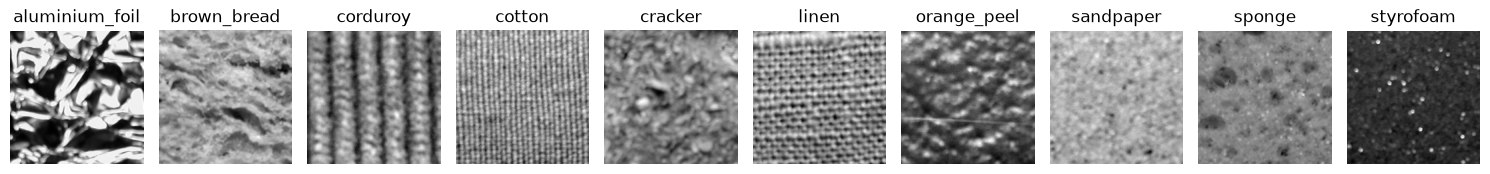

In [63]:
fig, axes = plt.subplots(1, len(CLASSES), figsize=(15, 3))

for ax, class_name in zip(axes, CLASSES):
    image = X[y == class_name][0]
    ax.imshow(image, cmap="gray")
    ax.set_title(class_name)
    ax.axis("off")

plt.tight_layout()
plt.show()

## Podział na zbiór uczący i testowy

In [64]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

print("Train set:", X_train.shape, y_train.shape)
print("Test set: ", X_test.shape, y_test.shape)

Train set: (648, 200, 200) (648,)
Test set:  (162, 200, 200) (162,)


# Ekstrakcja cech

In [65]:
from skimage.feature import graycomatrix, graycoprops

def image_features(image):
    image = image // 8 # 256 / 8 = 32 grayscale level reduction

    glcm = graycomatrix(
        image,
        distances=[1, 2, 3, 4],
        angles=[0, np.pi / 4, np.pi / 2, 3 * np.pi / 4],
        levels=32,
        symmetric=True,
        normed=True,
    )

    properties = ["contrast", "energy", "homogeneity", "correlation"]
    return np.concatenate([
        graycoprops(glcm, prop).ravel()
        for prop in properties
    ])

In [66]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

def extract_features(images):
    return np.array([
        image_features(image)
        for image in images
    ])

pipeline_forest = Pipeline([
    ('features', FunctionTransformer(extract_features, validate=False)),
    ('classifier', RandomForestClassifier())
])

pipeline_logistic = Pipeline([
    ('features', FunctionTransformer(extract_features, validate=False)),
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(max_iter=1000))
])

In [67]:
pipeline_forest.fit(X_train, y_train)
pipeline_logistic.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[<U14](10,)","['aluminium_foil','brown_bread','corduroy',...,'sandpaper','sponge', 'styrofoam']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,200
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function ext...x7f295598bf60>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False


In [68]:
y_pred_forest = pipeline_forest.predict(X_test)
y_pred_logistic = pipeline_logistic.predict(X_test)

In [69]:
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

                precision    recall  f1-score   support

aluminium_foil       1.00      1.00      1.00        16
   brown_bread       0.82      0.88      0.85        16
      corduroy       0.69      0.69      0.69        16
        cotton       0.92      0.71      0.80        17
       cracker       0.80      0.75      0.77        16
         linen       0.81      0.81      0.81        16
   orange_peel       0.81      1.00      0.89        17
     sandpaper       0.71      0.75      0.73        16
        sponge       0.82      0.88      0.85        16
     styrofoam       0.93      0.81      0.87        16

      accuracy                           0.83       162
     macro avg       0.83      0.83      0.83       162
  weighted avg       0.83      0.83      0.83       162



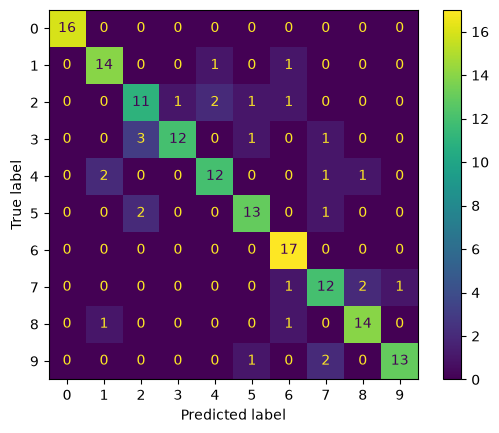

In [70]:
print(classification_report(y_test, y_pred_forest))
cm = confusion_matrix(y_test, y_pred_forest)
ConfusionMatrixDisplay(cm).plot()

                precision    recall  f1-score   support

aluminium_foil       1.00      1.00      1.00        16
   brown_bread       0.58      0.69      0.63        16
      corduroy       0.71      0.62      0.67        16
        cotton       0.83      0.59      0.69        17
       cracker       0.88      0.88      0.88        16
         linen       0.87      0.81      0.84        16
   orange_peel       0.88      0.88      0.88        17
     sandpaper       0.62      0.62      0.62        16
        sponge       0.74      0.88      0.80        16
     styrofoam       0.61      0.69      0.65        16

      accuracy                           0.77       162
     macro avg       0.77      0.77      0.77       162
  weighted avg       0.77      0.77      0.77       162



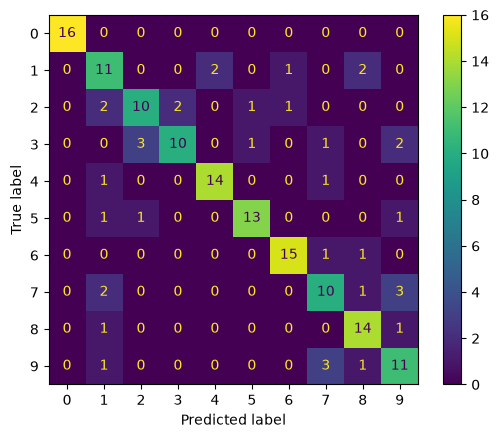

In [77]:
print(classification_report(y_test, y_pred_logistic))
cm = confusion_matrix(y_test, y_pred_logistic, labels=CLASSES)
ConfusionMatrixDisplay(cm).plot()

## Segmentacja przesuwnym oknem

In [72]:
WINDOW_SIZE = 50

def create_training_patches(images, labels, window_size=WINDOW_SIZE, step=100):
    patches = []
    patch_labels = []

    for image, label in zip(images, labels):
        for y in range(0, image.shape[0] - window_size + 1, step):
            for x in range(0, image.shape[1] - window_size + 1, step):
                patches.append(image[y:y + window_size, x:x + window_size])
                patch_labels.append(label)

    return np.array(patches), np.array(patch_labels)


X_train_patches, y_train_patches = create_training_patches(X_train, y_train)
print(X_train_patches.shape, y_train_patches.shape)

(2592, 50, 50) (2592,)


In [73]:
from sklearn.base import clone

segmentation_pipeline = clone(pipeline_forest)
segmentation_pipeline.fit(X_train_patches, y_train_patches)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[<U14](10,)","['aluminium_foil','brown_bread','corduroy',...,'sandpaper','sponge', 'styrofoam']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,50
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function ext...x7f295598bf60>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False


In [74]:
def sliding_window_segmentation(image, model, window_size=WINDOW_SIZE, step=20):
    radius = window_size // 2
    padded = cv2.copyMakeBorder(
        image, radius, radius, radius, radius, cv2.BORDER_REFLECT
    )

    y_positions = range(0, image.shape[0], step)
    x_positions = range(0, image.shape[1], step)
    patches = [
        padded[y:y + window_size, x:x + window_size]
        for y in y_positions
        for x in x_positions
    ]

    predictions = model.predict(np.array(patches))
    predictions = predictions.reshape(len(y_positions), len(x_positions))

    class_to_id = {class_name: index for index, class_name in enumerate(CLASSES)}
    label_grid = np.array([
        [class_to_id[label] for label in row]
        for row in predictions
    ], dtype=np.uint8)

    return cv2.resize(
        label_grid,
        (image.shape[1], image.shape[0]),
        interpolation=cv2.INTER_NEAREST,
    )

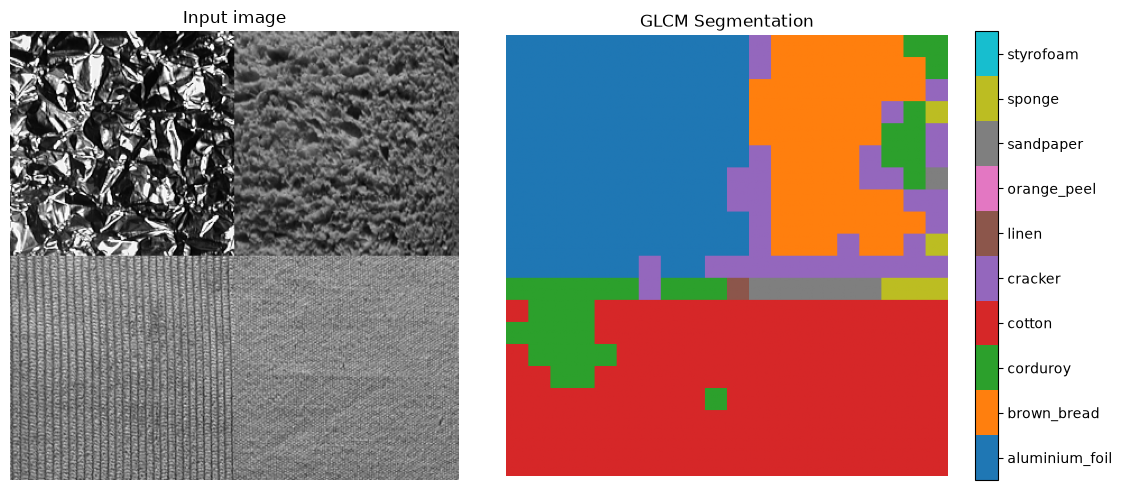

In [75]:
examples = [X_test[y_test == class_name][0] for class_name in CLASSES[:4]]
texture_mosaic = np.block([
    [examples[0], examples[1]],
    [examples[2], examples[3]],
])
segmentation_mask = sliding_window_segmentation(
    texture_mosaic, segmentation_pipeline
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(texture_mosaic, cmap="gray")
axes[0].set_title("Input image")
axes[0].axis("off")

result = axes[1].imshow(
    segmentation_mask, cmap="tab10", vmin=-0.5, vmax=len(CLASSES) - 0.5
)
axes[1].set_title("GLCM Segmentation")
axes[1].axis("off")

colorbar = fig.colorbar(result, ax=axes[1], ticks=range(len(CLASSES)))
colorbar.ax.set_yticklabels(CLASSES)
plt.tight_layout()
plt.show()